In [1]:
import os
import math

import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt

In [2]:
_dir = '/home/jan/Documents/EPFL/project_2/data/labels/dataset_v3'


In [3]:
_dir = '/home/jan/Documents/EPFL/project_2/data/labels/'

dfs = []
for _file in os.listdir(_dir):
    if not _file.endswith('.csv'):
        continue
    if _file in ['labels.csv', 'cocoa_th_65.csv']:
        continue
    print(_file)
    df = pd.read_csv(os.path.join(_dir, _file))
    dfs.append(df)


rubber.csv
mapbiomas.csv
vancutsem_regrowth.csv
laos_shifting_agriculture.csv
CAFI.csv
coffee_maskell.csv
mapbiomas_indonesia.csv
cocoa_th_90.csv
palm_oil.csv


In [4]:
df = pd.concat(dfs)

In [5]:
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])


In [6]:
gdf = gpd.GeoDataFrame(df)
gdf['geometry'] = gdf.geometry.centroid

In [7]:
gdf = gdf.reset_index(drop=True)

In [8]:
cls, count = np.unique(gdf.driver, return_counts=True)


for i in range(len(cls)):
    print(cls[i], count[i])

cocoa 9633
coffee 336
forest plantation 54480
forest regrowth 41219
mining 5050
other 68
palm oil 354997
pasture 528879
rubber 42967
shifting agriculture 3449
soy 47453
urban 2866


In [85]:
#For now, not sure about the class 'other', would need more examples of that (can do with mapb)

gdf = gdf.loc[gdf.driver != 'other']

In [88]:
df = gdf

In [90]:
driver_classes = np.unique(df.driver, return_counts=True)[0]
max_count_per_class = 5000
def flatten(nested_list):
    return [x for xs in nested_list for x in xs]


indices = []
for _class in driver_classes:
    try:
        class_samples = df.loc[df.driver == _class].sample(max_count_per_class, random_state=1).index
    except ValueError:
        class_samples = df.loc[df.driver == _class].index
    indices.append(class_samples.tolist())

indices = flatten(indices)

subset = df.loc[indices]

In [92]:
cls, count = np.unique(subset.driver, return_counts=True)


for i in range(len(cls)):
    print(cls[i], count[i])

cocoa 5000
coffee 336
forest plantation 5000
forest regrowth 5000
mining 5000
palm oil 5000
pasture 5000
rubber 5000
shifting agriculture 3449
soy 5000
urban 2866


In [100]:
_dir = '/home/jan/Documents/EPFL/project_2/data/labels/dataset_v3'


In [101]:
pd.DataFrame(subset).to_csv(_dir + '/labels.csv', index=False)

## Data split

In [103]:
def split_by_longitude(df, split =[ 'train', 'train', 'train','val']):
    # Splits dataset into train, val and test by degrees of latitude
    
    try:
        df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])
    except TypeError: #if already a GeoSeries
        df['geometry'] = gpd.GeoSeries(df['geometry'])
    
    df['lon'] = df.geometry.apply(lambda geom: math.floor(geom.x)) 

    for i, lon in enumerate(range(-180, 180)):
        df.loc[df['lon'] == lon, 'split'] = split[i%len(split)]
    
    df = df.drop('lon', axis=1)
    return df
    #return df.loc[df.split == 'Tr'].copy(), df.loc[df.split == 'Val'].copy(), df.loc[df.split == 'T'].copy()

In [107]:
df = split_by_longitude(subset)

In [105]:
#gpd.GeoDataFrame(df).to_file('../data/tmp/data_split.gpkg')

['cocoa' 'coffee' 'forest plantation' 'forest regrowth' 'mining'
 'palm oil' 'pasture' 'rubber' 'shifting agriculture' 'soy' 'urban'] [4558  308 3970 3770 3013 3689 3867 3503 2776 3431 1870]
['cocoa' 'coffee' 'forest plantation' 'forest regrowth' 'mining'
 'palm oil' 'pasture' 'rubber' 'shifting agriculture' 'soy' 'urban'] [ 442   28 1030 1230 1987 1311 1133 1497  673 1569  996]


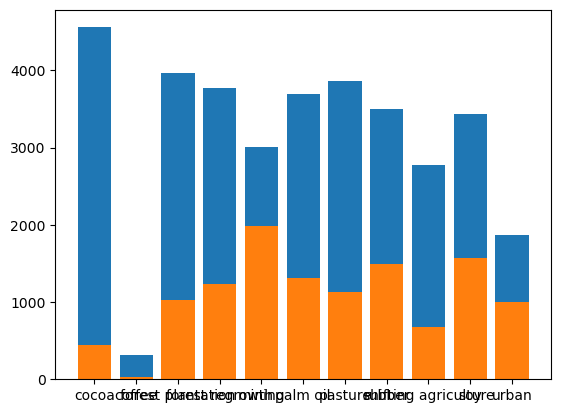

In [109]:
for dst in ['train', 'val']:
    
    classes, counts = np.unique(df.loc[df.split == dst].driver, return_counts=True)
    print(classes, counts)
    plt.bar(classes, height=counts)


In [110]:
df.to_csv(_dir + '/labels.csv', index=False)

In [3]:
df = pd.read_csv(_dir + '/labels.csv')

In [10]:
df

,geometry,driver,sampleid,split
0,POINT (-6.72678 5.50537),cocoa,3039418,train
1,POINT (-6.11368 5.47707),cocoa,3040124,train
2,POINT (-2.31246 5.53367),cocoa,3038914,train
3,POINT (-7.06634 6.10904),cocoa,3026449,train
4,POINT (-5.81185 6.35428),cocoa,3020208,train
...,...,...,...,...
46646,POINT (26.86901 -10.54303),urban,6000414,train
46647,POINT (9.84908 2.64657),urban,6000461,train
46648,POINT (12.56155 6.36398),urban,6000496,train
46649,POINT (25.41401 -10.42419),urban,6000553,train


In [8]:
df['geometry'] = gpd.GeoSeries.from_wkt(df['geometry'])


In [9]:
#gdf = gpd.GeoDataFrame(df)
gpd.GeoDataFrame(df).to_file('../data/tmp/dst_v3.gpkg')